<a href="https://colab.research.google.com/github/moysessevan/termodinamica-python/blob/main/cod_2_4_diagrama_Ph_r134a.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

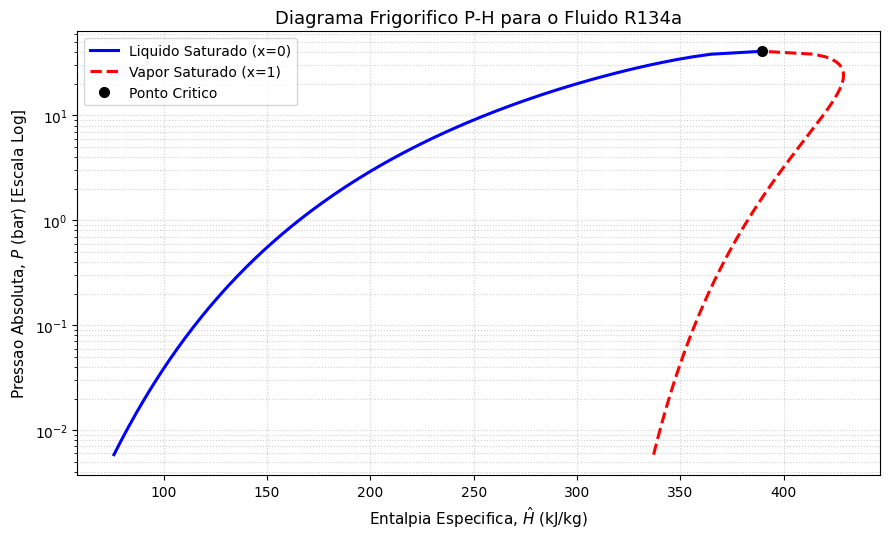

In [1]:
!pip install CoolProp --quiet
import numpy as np
import matplotlib.pyplot as plt
from CoolProp.CoolProp import PropsSI

# Diagrama P-h para o fluido refrigerante R134a
ref = 'R134a'
P_c = PropsSI('Pcrit', ref)
T_c = PropsSI('Tcrit', ref)
rho_c = PropsSI('rhocrit', ref)
h_c = PropsSI('H', 'T', T_c, 'D', rho_c, ref) / 1000.0  # kJ/kg
P_min = PropsSI('ptriple', ref) * 1.5

p_vet = np.logspace(np.log10(P_min), np.log10(P_c - 500), 150)
hf_vet = [PropsSI('H', 'P', p, 'Q', 0, ref) / 1000.0 for p in p_vet]
hg_vet = [PropsSI('H', 'P', p, 'Q', 1, ref) / 1000.0 for p in p_vet]

plt.figure(figsize=(9, 5.5))
plt.plot(hf_vet, p_vet / 1e5, 'b-', linewidth=2.2, label='Liquido Saturado (x=0)')
plt.plot(hg_vet, p_vet / 1e5, 'r--', linewidth=2.2, label='Vapor Saturado (x=1)')
plt.plot(h_c, P_c / 1e5, 'ko', markersize=7, label='Ponto Critico')

plt.yscale('log')
plt.xlabel(r'Entalpia Especifica, $\hat{H}$ ($\mathrm{kJ/kg}$)', fontsize=11)
plt.ylabel(r'Pressao Absoluta, $P$ ($\mathrm{bar}$) [Escala Log]', fontsize=11)
plt.title(f'Diagrama Frigorifico P-H para o Fluido {ref}', fontsize=13)
plt.grid(True, which='both', linestyle=':', alpha=0.6)
plt.legend(loc='best')
plt.tight_layout()
plt.show()